In [4]:
# Konfiguracja wyglądu punktów na wykresach
POINT_STYLES = {
    "stations": {"color": "#80C4E9", "size": 30, "alpha": 0.50},
    "binned": {"color": "#102A43", "size": 50, "alpha": 0.7},
    "excluded": {"facecolor": "white", "edgecolor": "#102A43", "size": 50, "alpha": 0.7},
}

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def _apply_project_plot_style():
    current = Path.cwd()
    for path in [current, *current.parents]:
        if (path / "plot_style.py").is_file():
            if str(path) not in sys.path:
                sys.path.insert(0, str(path))

            import plot_style

            plot_style.apply_montserrat_style()
            return

_apply_project_plot_style()

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "log_binning_aw.py").is_file():
        if str(path) not in sys.path:
            sys.path.insert(0, str(path))
        break
else:
    raise FileNotFoundError("Could not find log_binning_aw.py")

from log_binning_aw import log_binning_aw

In [5]:
def find_project_root(start=None):
    current = Path.cwd() if start is None else Path(start)
    for path in [current, *current.parents]:
        if (path / "Data").exists():
            return path
    raise FileNotFoundError("Could not find project root containing Data/")


PROJECT_ROOT = find_project_root()
BASE_DIR = PROJECT_ROOT
DATA_DIR = PROJECT_ROOT / "Data"
DATA_FILE = DATA_DIR / "rides_data_without_discontinuities.parquet"

rides_data = pd.read_parquet(DATA_FILE, columns=[
    "start_station_id", "start_station_name", "start_date", "start_day_of_week"
])

In [6]:
may_2024 = rides_data[
    (rides_data["start_date"].dt.year == 2024) &
    (rides_data["start_date"].dt.month == 5)
]

# Zamiana kolumny "start_date" na typ daty bez czasu
may_2024["start_date"] = may_2024["start_date"].dt.date

may_2024.head(-5)

,start_station_id,start_station_name,start_date,start_day_of_week
166,1199,"The Tennis Courts, The Regent's Park",2024-05-01,Wednesday
167,2691,"Howland Street, Fitzrovia",2024-05-01,Wednesday
168,1194,"Westminster University, Marylebone",2024-05-01,Wednesday
169,1091,"St. John's Wood Church, The Regent's Park",2024-05-02,Thursday
170,1153,"Pall Mall East, West End",2024-05-02,Thursday
...,...,...,...,...
14905575,200012,"Stepney Green Station, Stepney",2024-05-30,Thursday
14905576,300056,"Mile End Stadium, Mile End",2024-05-31,Friday
14905577,1153,"Pall Mall East, West End",2024-05-31,Friday
15202763,300207,"Gauden Road, Clapham",2024-05-30,Thursday


In [7]:
# Czy stacja była aktywna przez cały miesiąc?

station_activity = (
    may_2024
    .groupby("start_station_id")["start_date"]
    .agg(days_with_rides="nunique")
)

station_activity.head(-5)

,days_with_rides
start_station_id,
959,31
960,31
961,31
962,31
963,31
...,...
300242,31
300243,31
300244,31


In [8]:
# Wybieramy tylko stacje, które były aktywne przez cały miesiąc

valid_stations = station_activity[station_activity["days_with_rides"] == 31].index
may_2024_filtered = may_2024[may_2024["start_station_id"].isin(valid_stations)]
may_2024_filtered.head(-5)

,start_station_id,start_station_name,start_date,start_day_of_week
166,1199,"The Tennis Courts, The Regent's Park",2024-05-01,Wednesday
167,2691,"Howland Street, Fitzrovia",2024-05-01,Wednesday
168,1194,"Westminster University, Marylebone",2024-05-01,Wednesday
169,1091,"St. John's Wood Church, The Regent's Park",2024-05-02,Thursday
170,1153,"Pall Mall East, West End",2024-05-02,Thursday
...,...,...,...,...
14905575,200012,"Stepney Green Station, Stepney",2024-05-30,Thursday
14905576,300056,"Mile End Stadium, Mile End",2024-05-31,Friday
14905577,1153,"Pall Mall East, West End",2024-05-31,Friday
15202763,300207,"Gauden Road, Clapham",2024-05-30,Thursday


In [9]:
# Policzenie liczby przejazdów dla każdej stacji dzień po dniu
daily_rides_per_station = (
    may_2024_filtered
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)

# Wszystkie dni maja 2024 i wszystkie analizowane stacje
days = pd.date_range("2024-05-01", "2024-05-31", freq="D").date
station_ids = may_2024_filtered["start_station_id"].unique()

# Uzupełnienie brakujących dni i stacji zerami
daily_rides_per_station = daily_rides_per_station.reindex(
    index=station_ids, columns=days
).fillna(0)


In [10]:
daily_rides_per_station.head(2)

start_date,2024-05-01,2024-05-02,2024-05-03,2024-05-04,2024-05-05,2024-05-06,2024-05-07,2024-05-08,2024-05-09,2024-05-10,...,2024-05-22,2024-05-23,2024-05-24,2024-05-25,2024-05-26,2024-05-27,2024-05-28,2024-05-29,2024-05-30,2024-05-31
start_station_id,,,,,,,,,,,,,,,,,,,,,
1199,35,26,11,65,65,16,39,56,44,65,...,6,19,54,81,48,73,18,41,26,15
2691,48,52,18,20,17,15,50,25,37,28,...,34,64,63,24,31,17,39,65,48,49


In [11]:
# Średnia i wariancja dla każdej stacji

mean_and_variance_counts = pd.DataFrame({
    "mean_count": daily_rides_per_station.mean(axis=1),
    "variance": daily_rides_per_station.var(axis=1, ddof=0)
}).reset_index()

mean_and_variance_counts.head()

,start_station_id,mean_count,variance
0,1199,40.322581,521.895942
1,2691,40.000000,291.354839
2,1194,20.000000,44.838710
3,1091,22.096774,104.990635
4,1153,44.677419,574.928200


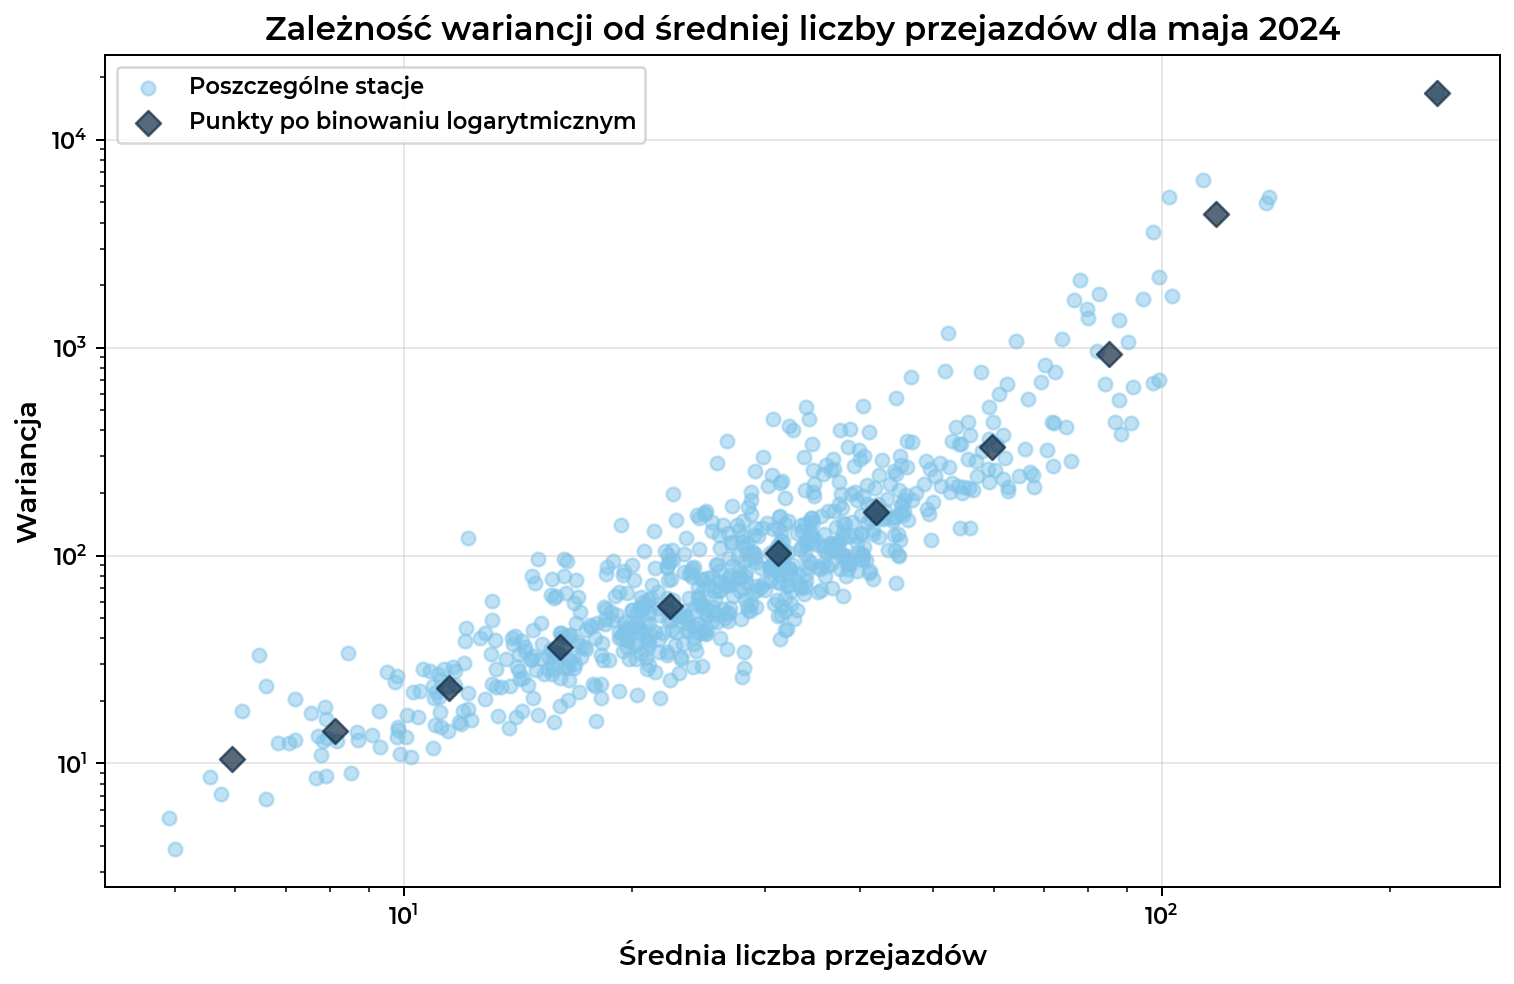

In [12]:
# Logarytmiczne przedziały
mean_log, variance_log = log_binning_aw(
    mean_and_variance_counts["mean_count"],
    mean_and_variance_counts["variance"],
    a=1.4
)

# Wykres
plt.figure(figsize=(10, 6))

# Chmura punktów
plt.scatter(
    mean_and_variance_counts["mean_count"], 
    mean_and_variance_counts["variance"],
    color=POINT_STYLES["stations"]["color"],
    alpha=POINT_STYLES["stations"]["alpha"],
    s=POINT_STYLES["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu logarytmicznym
plt.scatter(
    mean_log, 
    variance_log,
    color=POINT_STYLES["binned"]["color"],
    alpha=POINT_STYLES["binned"]["alpha"],
    marker="D",
    s=POINT_STYLES["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Średnia liczba przejazdów")
plt.ylabel("Wariancja")
plt.title("Zależność wariancji od średniej liczby przejazdów dla maja 2024")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Logarytmiczne przedziały
mean_log, variance_log = log_binning_aw(
    mean_and_variance_counts["mean_count"],
    mean_and_variance_counts["variance"],
    a=1.4
)

# Dopasowanie linii regresji do punktów po binowaniu logarytmicznym
x = np.log(mean_log)
y = np.log(variance_log)

alpha, log_A = np.polyfit(x, y, 1)
A = np.exp(log_A)

# Ocena jakości dopasowania w skali logarytmicznej
y_pred = alpha * x + log_A
ss_res = np.sum((y - y_pred)**2)
ss_tot = np.sum((y - np.mean(y))**2)
r_squared = 1 - ss_res / ss_tot
r_squared_str = f"{r_squared:.3f}".replace(".", ",")

# Dopasowana prosta - generowanie punktów do wykresu
x_fit = np.geomspace(min(mean_log), max(mean_log), 100)
y_fit = A * x_fit ** alpha

# Wykres
plt.figure(figsize=(10, 6))

# Chmura punktów
plt.scatter(
    mean_and_variance_counts["mean_count"], 
    mean_and_variance_counts["variance"],
    color=POINT_STYLES["stations"]["color"],
    alpha=POINT_STYLES["stations"]["alpha"],
    s=POINT_STYLES["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu logarytmicznym
plt.scatter(
    mean_log, 
    variance_log,
    color=POINT_STYLES["binned"]["color"],
    alpha=POINT_STYLES["binned"]["alpha"],
    marker="D",
    s=POINT_STYLES["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

alpha_str = f"{alpha:.3f}".replace(".", ",")

# Dopasowana funkcja potęgowa
plt.plot(
    x_fit,
    y_fit,
    color="#8054A3",
    linewidth=2.5,
    zorder=2,
    label=fr"Dopasowanie: $\alpha = {alpha_str}$; $R^2 = {r_squared_str}$"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Średnia liczba przejazdów")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla maja 2024")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Binowanie logarytmiczne
mean_log, variance_log = log_binning_aw(
    mean_and_variance_counts["mean_count"],
    mean_and_variance_counts["variance"],
    a=1.4
)

# Dopasowanie prawa Taylora z pominięciem ostatniego punktu
x = np.log(mean_log[:-1])
y = np.log(variance_log[:-1])

alpha, log_A = np.polyfit(x, y, 1)
A = np.exp(log_A)

# Ocena jakości dopasowania w skali logarytmicznej
y_pred = alpha * x + log_A
ss_res = np.sum((y - y_pred)**2)
ss_tot = np.sum((y - np.mean(y))**2)
r_squared = 1 - ss_res / ss_tot
r_squared_str = f"{r_squared:.3f}".replace(".", ",")

# Generowanie punktów dopasowanej funkcji
x_fit = np.geomspace(min(mean_log[:-1]), max(mean_log[:-1]), 100)
y_fit = A * x_fit**alpha

# Wykres
plt.figure(figsize=(10, 6))

# Chmura punktów – poszczególne stacje
plt.scatter(
    mean_and_variance_counts["mean_count"],
    mean_and_variance_counts["variance"],
    color=POINT_STYLES["stations"]["color"],
    alpha=POINT_STYLES["stations"]["alpha"],
    s=POINT_STYLES["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu uwzględnione w dopasowaniu
plt.scatter(
    mean_log[:-1],
    variance_log[:-1],
    color=POINT_STYLES["binned"]["color"],
    alpha=POINT_STYLES["binned"]["alpha"],
    marker="D",
    s=POINT_STYLES["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

# Ostatni punkt pominięty w dopasowaniu
plt.scatter(
    mean_log[-1],
    variance_log[-1],
    marker="D",
    facecolors=POINT_STYLES["excluded"]["facecolor"],
    edgecolors=POINT_STYLES["excluded"]["edgecolor"],
    alpha=POINT_STYLES["excluded"]["alpha"],
    linewidths=2,
    s=POINT_STYLES["excluded"]["size"],
    zorder=3,
    label="Punkt pominięty w dopasowaniu"
)

alpha_str = f"{alpha:.3f}".replace(".", ",")

# Dopasowana funkcja potęgowa
plt.plot(
    x_fit,
    y_fit,
    color="#8054A3",
    linewidth=2.5,
    zorder=2,
    label=fr"Dopasowanie: $\alpha = {alpha_str}$; $R^2 = {r_squared_str}$"
)

# Skala logarytmiczna
plt.xscale("log")
plt.yscale("log")

# Opisy wykresu
plt.xlabel("Średnia dzienna liczba wypożyczeń")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla maja 2024 - pominięcie ostatniego punktu w dopasowaniu")

plt.grid(alpha=0.3)
plt.legend()
plt.show()